## Visualization of CDK4/6i simulations

In [1]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import os
from pathlib import Path
import re
import sys
import joblib

from random import randint

### Set global variables

In [2]:
SAVEFILES = True
OVERWRITE = False
USE_ORIGINAL = True # If False, will look for user-generated data in SAVE_DIR, else will pull from Data directory in repo

SAVE_DIR = Path("~/ECM_mod_output/").expanduser()
    
rcParams.update({'figure.autolayout': True})

sys_type = sys.platform

if sys_type == 'darwin':
    sys_name = 'mac'
if sys_type == 'win32': 
    sys_name = 'win'
if sys_type == 'linux': 
    sys_name = sys_type

stoch_embed_fn = Path('../../Data/UMAP_embeddings/all_embedding_stoch_cdk46i.sav')
ode_embed_fn = Path(str(stoch_embed_fn).replace('stoch', 'ode'))


### Load UMAP embedding of CDK4/6i data
UMAP embeddings should be `SAVE_DIR`. If they are not detected, they will be downloaded automatically.  

Order of samples in data:  
1) soft DMSO
1) int DMSO 
1) stiff DMSO
1) soft ERL
1) int ERL
1) stiff ERL
1) stiff CDK4/6i
1) stiff ERL + CDK4/6i


In [3]:
embed_dat = joblib.load(stoch_embed_fn)
stoch_l = int(len(embed_dat)/8)
stoch_l

39993

In [4]:
embed_dat_ode = joblib.load(ode_embed_fn)
ode_l = int(len(embed_dat_ode)/8)
ode_l

2000

In [5]:
def get_traj(embed_dat, pos, trk_len):
    if pos > len(embed_dat)/trk_len:
        print('Position out of range')
        return np.nan   
    embed_traj = embed_dat[pos*trk_len:(pos+1)*trk_len]
    return embed_traj

(-7.0, 12.0)

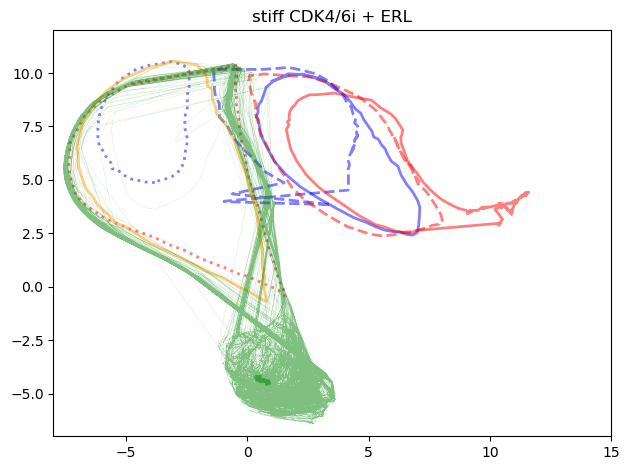

In [6]:
col = ['blue','blue','blue','red','red','red','orange','green']
plot_ode_len = [60, 50, 45, 150, 70, 60, 70, 150]
ode_lsty = ['solid', 'dashed', 'dotted', 'solid', 'dashed', 'dotted', 'solid', 'solid']
cond = ['soft DMSO', 'int DMSO',' stiff DMSO','soft ERL', 'int ERL', 'stiff ERL', 'stiff CDK4/6i', 'stiff CDK4/6i + ERL']


for i in range(8):
    plt.plot(embed_dat_ode[i*ode_l:(i*ode_l+plot_ode_len[i]),0], 
             embed_dat_ode[i*ode_l:(i*ode_l+plot_ode_len[i]),1], 
             color=col[i], lw=2, linestyle=ode_lsty[i], alpha=0.5)
    
pos = 7
embed_plot = get_traj(embed_dat, pos, stoch_l)

plt.title(cond[pos])
plt.plot(embed_plot[:,0], embed_plot[:,1], lw=0.1, color=col[pos], alpha=0.5)

plt.xlim(-8,15)
plt.ylim(-7,12)
